# クラスタリング (基準となる結果)

## 目的

[ADR 008](../docs/decisions/008_feature_selection.md) で選んだ 8 つの特徴量と、[ADR 009](../docs/decisions/009_clustering_preprocessing.md) で決めた前処理で K-means を行い、**基準となる結果**を作る。
重みの調整などはせず、この結果を出発点として、何で顧客が分かれたかを確認する。

## 確認すること (ADR 008 の「次の段階で確認すること」)

1. 標準化の前後の値の分布
2. クラスタ数ごとの評価 (まとまりの良さ、シルエット係数、初期値を変えたときの安定性)
3. クラスタごとの顧客数・構成比と、特徴量の平均・中央値
4. 各特徴量が、クラスタの分割にどれだけ効いたか

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する
features = client.query("select * from olist_mart.customer_features").to_dataframe()
features.shape

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(93358, 22)

## 1. 前処理

ADR 009 のとおりに前処理する。

- NULL が 1 つでもある顧客は、学習から外す
- `total_items_amount`・`order_count`・`item_count` は対数変換 (log1p) する
- 真偽値の `has_review_comment` は 0 / 1 にする
- すべての特徴量を標準化する (平均と標準偏差は、学習に使う顧客から計算する)

In [2]:
FEATURES = [
    "total_items_amount",
    "order_count",
    "item_count",
    "days_since_last_purchase",
    "credit_card_order_ratio",
    "avg_review_score",
    "has_review_comment",
    "late_delivery_ratio",
]
LOG_FEATURES = ["total_items_amount", "order_count", "item_count"]

# 加工前の値 (クラスタの解釈に使う)。NUMERIC は Decimal、真偽値は boolean として読まれるため float にする
raw = features[FEATURES].astype("float")

is_complete = raw.notna().all(axis=1)
train_raw = raw[is_complete]
print(f"全体: {len(raw):,} 人 / 学習に使う: {len(train_raw):,} 人 / 外す: {(~is_complete).sum():,} 人")

transformed = train_raw.copy()
transformed[LOG_FEATURES] = np.log1p(transformed[LOG_FEATURES])
Z = (transformed - transformed.mean()) / transformed.std(ddof=0)

全体: 93,358 人 / 学習に使う: 92,745 人 / 外す: 613 人


### 標準化の前後の値の分布

標準化したあとは、どの特徴量も平均 0・標準偏差 1 になる。
ただし、最小値と最大値の幅は特徴量によって大きく異なる。

In [3]:
pd.DataFrame({
    "raw_min": train_raw.min(),
    "raw_median": train_raw.median(),
    "raw_max": train_raw.max(),
    "z_min": Z.min(),
    "z_median": Z.median(),
    "z_max": Z.max(),
    "top_value_share": train_raw.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
}).round(2)

,raw_min,raw_median,raw_max,z_min,z_median,z_max,top_value_share
total_items_amount,0.85,89.7,13440.0,-4.19,0.02,5.44,0.02
order_count,1.00,1.0,15.0,-0.17,-0.17,26.89,0.97
item_count,1.00,1.0,24.0,-0.34,-0.34,13.18,0.88
days_since_last_purchase,0.00,218.0,695.0,-1.56,-0.13,3.00,0.01
credit_card_order_ratio,0.00,1.0,1.0,-1.83,0.55,0.55,0.77
avg_review_score,1.00,5.0,5.0,-2.46,0.66,0.66,0.59
has_review_comment,0.00,0.0,1.0,-0.86,-0.86,1.16,0.57
late_delivery_ratio,0.00,0.0,1.0,-0.27,-0.27,3.75,0.93


## 2. クラスタ数ごとの評価

k = 2〜8 で K-means を行い、次の指標を比べる。

- `inertia`: 各顧客とクラスタの中心との距離の二乗和 (小さいほどまとまりが良い。k を増やすと必ず小さくなる)
- `silhouette`: シルエット係数 (−1〜1。大きいほどクラスタどうしが分かれている)。計算量が大きいため、20,000 人を無作為に選んで計算する
- `ari_min`: 初期値 (乱数のシード) を変えた結果どうしの一致度 (調整ランド指数) の最小値。1 なら、どのシードでも同じ分け方になる

### 初期値の試行回数

K-means は初期値によって、最適ではない分け方 (局所解) で止まることがある。
`n_init` (初期値を変えて試す回数。最も inertia が小さい結果を採用する) を 10 にすると、シードによって結果が変わるかを先に確認する。

In [4]:
for k in (3, 4):
    inertias = [KMeans(n_clusters=k, n_init=10, random_state=seed).fit(Z).inertia_ for seed in range(10)]
    print(f"k={k}: n_init=10 の inertia (シード 0〜9) = {[round(x) for x in inertias]}")

k=3: n_init=10 の inertia (シード 0〜9) = [536937, 530934, 527380, 536937, 527380, 527380, 527383, 527383, 527383, 527380]


k=4: n_init=10 の inertia (シード 0〜9) = [440973, 442761, 440974, 442759, 440973, 440974, 465856, 440974, 440973, 440973]


`n_init=10` では、シードによって inertia が異なり、局所解で止まる場合がある。以降は `n_init=50` で行う。

In [5]:
K_RANGE = range(2, 9)
N_INIT = 50
SEEDS = (0, 1, 2)

models = {}
rows = []
for k in K_RANGE:
    runs = [KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit(Z) for seed in SEEDS]
    best = runs[0]
    models[k] = best
    rows.append({
        "k": k,
        "inertia": best.inertia_,
        "silhouette": silhouette_score(Z, best.labels_, sample_size=20_000, random_state=0),
        "ari_min": min(adjusted_rand_score(best.labels_, run.labels_) for run in runs[1:]),
        "sizes": sorted(np.bincount(best.labels_).tolist(), reverse=True),
    })

evaluation = pd.DataFrame(rows).set_index("k")
evaluation.round(3)

,inertia,silhouette,ari_min,sizes
k,,,,
2,631444.027,0.354,0.999,"[75267, 17478]"
3,527379.551,0.427,1.000,"[83673, 6051, 3021]"
4,440973.240,0.247,1.000,"[49397, 34455, 6051, 2842]"
5,376090.777,0.276,1.000,"[38182, 26464, 19212, 6051, 2836]"
6,333047.946,0.283,1.000,"[35209, 23147, 17972, 7604, 6021, 2792]"
7,305203.360,0.291,1.000,"[34150, 19818, 16599, 6971, 6395, 6020, 2792]"
8,280837.295,0.267,0.997,"[23455, 16946, 16586, 13748, 7033, 6166, 6019,..."


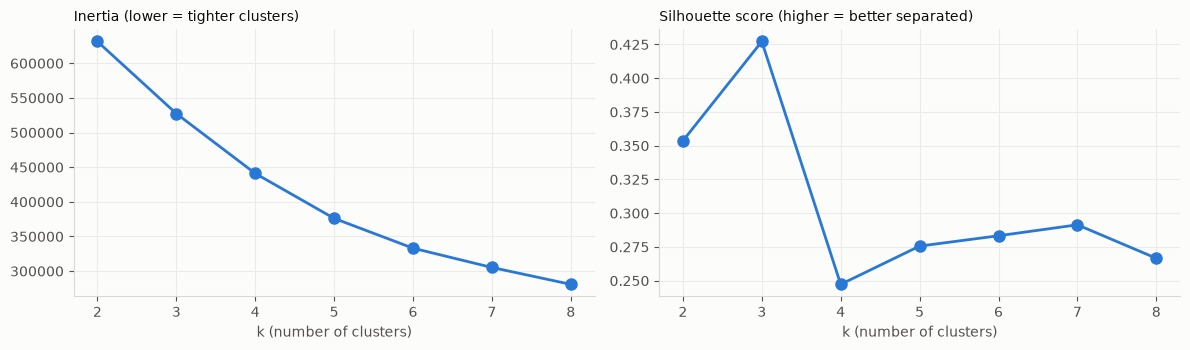

In [6]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SERIES = "#2a78d6"  # 単一系列のため 1 色のみ

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# 尺度の違う 2 つの指標は、軸を共有せずに別のグラフにする
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, metric, title in zip(
    axes,
    ("inertia", "silhouette"),
    ("Inertia (lower = tighter clusters)", "Silhouette score (higher = better separated)"),
):
    ax.plot(evaluation.index, evaluation[metric], color=SERIES, linewidth=2, marker="o", markersize=8)
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_xlabel("k (number of clusters)")
    ax.set_xticks(list(K_RANGE))
fig.tight_layout()
plt.show()

### 評価の考察

- inertia は k とともになだらかに減り、はっきりした折れ曲がり (エルボー) はない。
- シルエット係数は k = 3 が最も高く (0.43)、k = 4〜8 は 0.25〜0.29。
- `n_init=50` では、どの k でもシードを変えた結果がほぼ一致した (`ari_min` が 0.997 以上)。分け方は安定している。
- ただし、ADR 008 のとおり、シルエット係数が高いことだけを理由に良い結果とは判断しない。何で分かれたかを 3. と 4. で確認する。

## 3. クラスタごとの顧客数と特徴量

ADR 008 で試すとした k = 3〜6 について、クラスタごとに加工前の値の平均を見る。
クラスタの番号は、顧客数の多い順に付け直す。

In [7]:
def relabel_by_size(labels: np.ndarray) -> np.ndarray:
    """クラスタの番号を、顧客数の多い順に 0, 1, 2, ... と付け直す。"""
    order = pd.Series(labels).value_counts().index  # 顧客数の降順 (同数の場合は value_counts の順)
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[label] for label in labels])


labels = {k: relabel_by_size(models[k].labels_) for k in K_RANGE}


def profile(k: int, stat: str = "mean") -> pd.DataFrame:
    """クラスタごとの顧客数・構成比と、加工前の特徴量の平均 (または中央値) を返す。"""
    grouped = train_raw.assign(cluster=labels[k]).groupby("cluster")
    result = grouped.agg(stat).round(2)
    result.insert(0, "share", (grouped.size() / len(train_raw)).round(3))
    result.insert(0, "n", grouped.size())
    return result


for k in (3, 4, 5, 6):
    print(f"k={k} (平均)")
    display(profile(k))

k=3 (平均)


,n,share,total_items_amount,order_count,item_count,days_since_last_purchase,credit_card_order_ratio,avg_review_score,has_review_comment,late_delivery_ratio
cluster,,,,,,,,,,
0,83673,0.902,135.40,1.00,1.12,239.21,0.77,4.29,0.41,0.00
1,6051,0.065,150.61,1.00,1.11,220.07,0.76,2.26,0.60,1.00
2,3021,0.033,288.95,2.03,2.88,219.57,0.76,4.13,0.53,0.05


k=4 (平均)


,n,share,total_items_amount,order_count,item_count,days_since_last_purchase,credit_card_order_ratio,avg_review_score,has_review_comment,late_delivery_ratio
cluster,,,,,,,,,,
0,49397,0.533,130.25,1.00,1.11,240.56,0.77,4.49,0.00,0.00
1,34455,0.372,144.65,1.00,1.17,237.17,0.77,4.00,1.00,0.00
2,6051,0.065,150.61,1.00,1.11,220.07,0.76,2.26,0.60,1.00
3,2842,0.031,276.15,2.09,2.69,219.44,0.77,4.18,0.53,0.06


k=5 (平均)


,n,share,total_items_amount,order_count,item_count,days_since_last_purchase,credit_card_order_ratio,avg_review_score,has_review_comment,late_delivery_ratio
cluster,,,,,,,,,,
0,38182,0.412,135.68,1.0,1.10,239.18,1.00,4.50,0.00,0.00
1,26464,0.285,151.41,1.0,1.17,235.74,1.00,4.00,1.00,0.00
2,19212,0.207,116.29,1.0,1.14,243.85,0.00,4.28,0.42,0.00
3,6051,0.065,150.61,1.0,1.11,220.07,0.76,2.26,0.60,1.00
4,2836,0.031,275.28,2.1,2.68,219.55,0.77,4.18,0.53,0.06


k=6 (平均)


,n,share,total_items_amount,order_count,item_count,days_since_last_purchase,credit_card_order_ratio,avg_review_score,has_review_comment,late_delivery_ratio
cluster,,,,,,,,,,
0,35209,0.380,130.61,1.00,1.00,238.58,1.00,4.51,0.00,0.00
1,23147,0.250,143.98,1.00,1.00,236.42,1.00,4.13,1.00,0.00
2,17972,0.194,106.61,1.00,1.04,244.23,0.00,4.35,0.40,0.00
3,7604,0.082,216.23,1.00,2.46,238.05,0.83,3.60,0.54,0.00
4,6021,0.065,149.02,1.00,1.08,220.08,0.76,2.26,0.60,1.00
5,2792,0.030,259.68,2.11,2.57,219.54,0.77,4.20,0.53,0.06


中央値でも確認する (k = 6)。0 / 1 に近い特徴量は、平均だと「割合」として読める一方、中央値は 0 か 1 になる。

In [8]:
profile(6, "median")

,n,share,total_items_amount,order_count,item_count,days_since_last_purchase,credit_card_order_ratio,avg_review_score,has_review_comment,late_delivery_ratio
cluster,,,,,,,,,,
0,35209,0.380,82.99,1.0,1.0,222.0,1.0,5.00,0.0,0.0
1,23147,0.250,89.77,1.0,1.0,216.0,1.0,5.00,1.0,0.0
2,17972,0.194,68.90,1.0,1.0,229.0,0.0,5.00,0.0,0.0
3,7604,0.082,141.80,1.0,2.0,219.0,1.0,4.00,1.0,0.0
4,6021,0.065,89.99,1.0,1.0,190.0,1.0,1.00,1.0,1.0
5,2792,0.030,181.98,2.0,2.0,198.0,1.0,4.67,1.0,0.0


### クラスタの考察

- k を増やすと、それまでのクラスタはほとんど変わらず、新しいクラスタが 1 つずつ切り出される。
  - k = 3: 遅れを経験した顧客 (約 6,000 人、6.5%) と、複数回購入した顧客 (約 3,000 人、3.3%) が、残りの 90% から分かれる
  - k = 4: 残りが、レビューのコメントの有無で分かれる
  - k = 5: さらに、クレジットカードを使ったかどうかで分かれる
  - k = 6: 1 回の注文で複数の商品を買った顧客が分かれる
- 金額は、複数の商品を買った顧客や複数回購入した顧客のクラスタで大きいが、それ以外のクラスタの平均は 107〜151 で、大きな差はない。
- 最終購入からの日数の平均は、どのクラスタも 219〜244 日で、ほとんど差がない。

## 4. 何で顧客が分かれたか

特徴量ごとに、標準化したあとの値のばらつきのうち、クラスタの違いで説明できる割合 (R²) を計算する。

- R² = 1 − (クラスタ内のばらつき ÷ 全体のばらつき)
- 1 に近いほど、その特徴量はクラスタごとにはっきり値が分かれている (= 分割に効いている)
- 0 に近いほど、どのクラスタでも同じような値で、分割にほとんど使われていない

In [9]:
def r_squared(k: int) -> pd.Series:
    """標準化した各特徴量について、クラスタで説明できるばらつきの割合を返す。"""
    within = Z.groupby(labels[k]).transform(lambda s: s - s.mean()).pow(2).sum()
    total = Z.pow(2).sum()  # 標準化しているため、平均からの偏差の二乗和そのもの
    return 1 - within / total


r2 = pd.DataFrame({k: r_squared(k) for k in K_RANGE})
r2.round(2)

,2,3,4,5,6,7,8
total_items_amount,0.03,0.03,0.02,0.03,0.06,0.06,0.06
order_count,0.13,0.86,0.92,0.92,0.94,0.94,0.94
item_count,0.19,0.27,0.22,0.22,0.76,0.72,0.71
days_since_last_purchase,0.00,0.00,0.00,0.00,0.00,0.00,0.37
credit_card_order_ratio,0.00,0.00,0.00,0.91,0.84,0.78,0.78
avg_review_score,0.47,0.15,0.19,0.18,0.19,0.61,0.60
has_review_comment,0.07,0.01,0.90,0.70,0.63,0.62,0.53
late_delivery_ratio,0.31,0.98,0.99,0.99,0.98,0.98,0.98


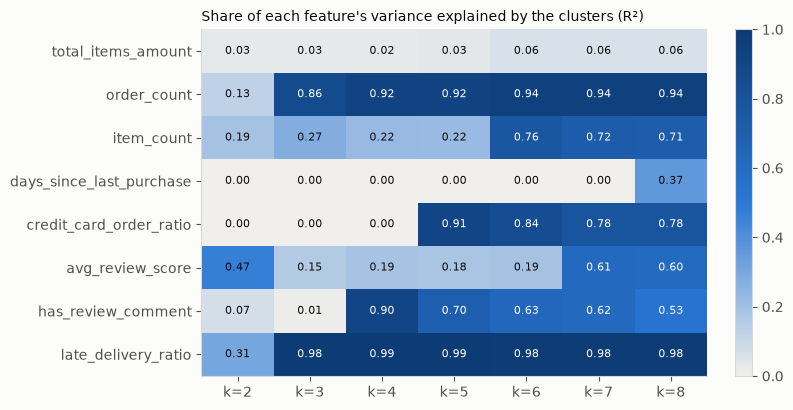

In [10]:
# R² は 0〜1 の大きさなので、1 色の濃淡で表す
sequential = LinearSegmentedColormap.from_list("sequential", ["#f0efec", "#2a78d6", "#0d3a73"])

fig, ax = plt.subplots(figsize=(8, 4.2))
image = ax.imshow(r2.to_numpy(), cmap=sequential, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(r2.columns)), [f"k={k}" for k in r2.columns])
ax.set_yticks(range(len(r2.index)), r2.index)
ax.grid(False)
for i in range(r2.shape[0]):
    for j in range(r2.shape[1]):
        value = r2.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if value > 0.5 else TEXT_PRIMARY)
ax.set_title("Share of each feature's variance explained by the clusters (R²)", fontsize=10, loc="left")
fig.colorbar(image, ax=ax, fraction=0.04)
fig.tight_layout()
plt.show()

### クラスタの中心 (k = 6)

標準化した値でのクラスタの平均を見る。0 から離れているほど、そのクラスタはその特徴量で全体の平均と異なる。

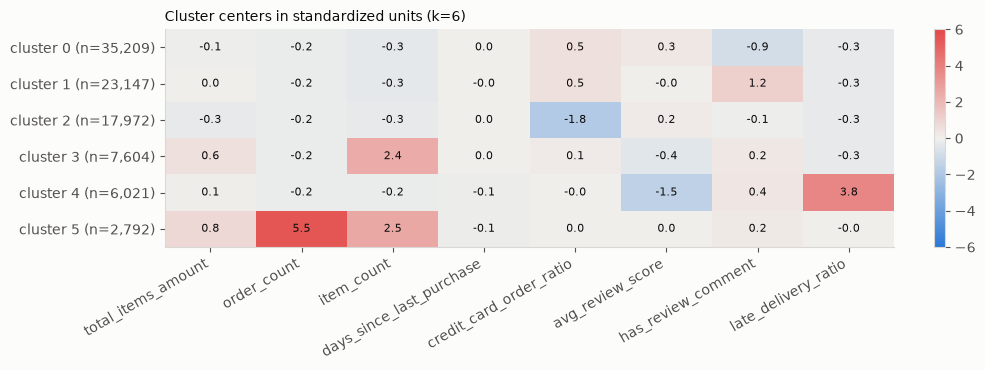

In [11]:
centers = Z.groupby(labels[6]).mean()

# 平均 (0) を境に正負を表すため、2 色 + 中央の灰色にする
diverging = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])
limit = np.ceil(centers.abs().to_numpy().max())

fig, ax = plt.subplots(figsize=(10, 3.8))
image = ax.imshow(centers.to_numpy(), cmap=diverging, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(centers.columns)), centers.columns, rotation=30, ha="right")
ax.set_yticks(range(len(centers.index)), [f"cluster {c} (n={n:,})" for c, n in zip(centers.index, np.bincount(labels[6]))])
ax.grid(False)
for i in range(centers.shape[0]):
    for j in range(centers.shape[1]):
        ax.text(j, i, f"{centers.iat[i, j]:.1f}", ha="center", va="center", fontsize=8, color=TEXT_PRIMARY)
ax.set_title("Cluster centers in standardized units (k=6)", fontsize=10, loc="left")
fig.colorbar(image, ax=ax, fraction=0.03)
fig.tight_layout()
plt.show()

### クラスタと、0 / 1 に近い特徴量の条件との対応 (k = 6)

クラスタごとに、次の条件を満たす顧客の割合を見る。1 または 0 に近いほど、そのクラスタは条件でほぼ説明できる。

In [12]:
conditions = pd.DataFrame({
    "repeat (order_count >= 2)": train_raw["order_count"] >= 2,
    "late (late_delivery_ratio > 0)": train_raw["late_delivery_ratio"] > 0,
    "multi_item (item_count >= 2)": train_raw["item_count"] >= 2,
    "card_always (credit_card_order_ratio = 1)": train_raw["credit_card_order_ratio"] == 1,
    "comment (has_review_comment)": train_raw["has_review_comment"] == 1,
})
summary = conditions.groupby(labels[6]).mean().round(3)
summary.insert(0, "n", np.bincount(labels[6]))
summary

,n,repeat (order_count >= 2),late (late_delivery_ratio > 0),multi_item (item_count >= 2),card_always (credit_card_order_ratio = 1),comment (has_review_comment)
0,35209,0.0,0.000,0.001,1.000,0.000
1,23147,0.0,0.000,0.000,1.000,1.000
2,17972,0.0,0.000,0.036,0.000,0.401
3,7604,0.0,0.004,1.000,0.833,0.543
4,6021,0.0,1.000,0.071,0.761,0.604
5,2792,1.0,0.107,1.000,0.725,0.528


In [13]:
# 条件を満たす顧客が、どのクラスタに入ったか (各条件の人数の内訳)
conditions.astype(int).groupby(labels[6]).sum().T.assign(total=lambda df: df.sum(axis=1))

,0,1,2,3,4,5,total
repeat (order_count >= 2),0,0,0,0,0,2792,2792
late (late_delivery_ratio > 0),0,0,0,31,6021,300,6352
multi_item (item_count >= 2),28,1,650,7604,430,2792,11505
card_always (credit_card_order_ratio = 1),35209,23147,0,6332,4582,2023,71293
comment (has_review_comment),0,23147,7214,4131,3636,1475,39603


### 何で分かれたかの考察

- R² を見ると、分割に効いているのは 0 / 1 に近い特徴量。
  - `late_delivery_ratio` は k = 3 以降 0.98 以上、`order_count` は 0.86 以上
  - `has_review_comment` は k = 4 で 0.90、`credit_card_order_ratio` は k = 5 で 0.91、`item_count` は k = 6 で 0.76
- 一方で、`total_items_amount` は 0.06 以下、`days_since_last_purchase` は k = 7 まで 0.00 で、分割にほとんど使われていない。
- k = 6 のクラスタは、ほぼ条件の組み合わせで書ける。
  - cluster 5: 複数回購入した顧客 (2,792 人の全員がこのクラスタ)
  - cluster 4: 1 回購入で、遅れを経験した顧客
  - cluster 3: 1 回購入で、複数の商品を買った顧客
  - cluster 0〜2: 1 回購入で、遅れがなく、ほぼ 1 商品だけを買った顧客が、カードの利用とコメントの有無で 3 つに分かれたもの
- 出現率の低い値ほど、標準化すると大きな値になる (例: `order_count` の最大は 26.9、`late_delivery_ratio` の 1 は 3.75)。そのため、距離はまれな 0 / 1 の値の違いに強く左右され、K-means はまれな値から順に切り出していると考えられる (ADR 008 の「前処理とフラグの影響」)。

## まとめ

- 基準となる結果は、**0 / 1 に近い特徴量 (リピート・遅れ・複数商品・カード・コメント) の組み合わせで、ほぼ決まる分け方**になった。条件を書くだけで作れる分け方と大きくは変わらない。
- 金額と最終購入からの日数は、分割にほとんど効いていない。
- シルエット係数は k = 3 で最も高いが、これはまれな値を持つ顧客がはっきり分かれているためで、顧客像として解釈しやすい分け方かは別に判断する必要がある。
- この結果だけでは、「購買行動で顧客をセグメンテーションできた」とは言えない。

## 次に確認すること

- 0 / 1 に近い特徴量の影響をどう扱うか (重みを下げる、条件で分けてから連続値でクラスタリングする、など)
- 学習から外した 613 人の扱い (ADR 009)